# 🏥 Marginal Inference with the Forward–Backward (Sum-Product) Algorithm
## POS Tagging on Clinical / Medical Text using a from-scratch Hidden Markov Model

**Goal.** For every word in an unstructured EHR sentence, compute the **exact posterior probability** of each Part-of-Speech tag,
$\gamma_t(i)=P(q_t=S_i \mid O,\lambda)$, and use these marginals to extract clinical information (symptoms, conditions, drugs, doses).

**Everything in the core algorithm is written from scratch in NumPy** (no HMM library calls): $\pi$, $A$, $B$, $\alpha$-pass, $\beta$-pass, $\gamma$-posterior.

### Pipeline

| Step | What happens |
|---|---|
| 1 | Load **NLTK Penn Treebank** (universal tagset, 12 tags) |
| 2 | Generate **synthetic EHR sentences** with gold tags (so we have clinical vocabulary + labelled clinical test data) |
| 3 | Estimate HMM parameters $\lambda=(\pi, A, B)$ by counting (supervised MLE + smoothing) |
| 4 | **Forward pass** → $\alpha$  |
| 5 | **Backward pass** → $\beta$ |
| 6 | **Marginal inference** → $\gamma$ (posterior of every tag at every word) |
| 7 | Verify exactness against brute-force enumeration |
| 8 | Evaluate (accuracy, confusion matrix), visualise, extract clinical entities |

### Notation used throughout

| Symbol | Meaning |
|---|---|
| $N$ | number of hidden states = number of POS tags (12) |
| $T$ | number of words in the sentence |
| $O=o_1,\dots,o_T$ | observed words |
| $q_t$ | hidden POS tag at position $t$ |
| $\pi_i=P(q_1=S_i)$ | initial state probability |
| $a_{ij}=P(q_t=S_j\mid q_{t-1}=S_i)$ | transition probability (each row sums to 1) |
| $b_i(o_t)=P(o_t\mid q_t=S_i)$ | emission probability |

## 1️⃣ Setup: dependencies and imports
The helper below installs a package only if it is missing, so the cell works on a fresh Colab runtime *and* on a local machine.
NLTK's Penn Treebank sample (≈3,900 sentences) is downloaded through NLTK's own downloader.

In [ ]:
import subprocess, sys, importlib

def ensure(pkg, module=None):
    """Install a package only if it cannot be imported."""
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

for pkg in ["nltk", "numpy", "pandas", "matplotlib", "seaborn"]:
    ensure(pkg)

import re, random, itertools, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

nltk.download("treebank", quiet=True)
nltk.download("universal_tagset", quiet=True)
from nltk.corpus import treebank
from nltk.tag import map_tag

SEED = 42
random.seed(SEED); np.random.seed(SEED)
np.set_printoptions(precision=4, suppress=True, linewidth=220)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
print("✅ Environment ready. NumPy", np.__version__, "| NLTK", nltk.__version__)

✅ Environment ready. NumPy 2.1.3 | NLTK 3.9.1


## 2️⃣ Dataset A: NLTK Penn Treebank (universal tagset)

The Penn Treebank has ~45 fine-grained tags. We map them to the **12-tag universal tagset**:

`NOUN, VERB, ADJ, ADV, PRON, DET, ADP, NUM, CONJ, PRT, '.', X`

Two preprocessing choices:
* Tokens tagged `-NONE-` (syntactic traces such as `*-1`, which are not real words) are removed.
* Words are **lower-cased**, and any number (`81`, `38.5`, `10,000`) is replaced by the single token `<NUM>`. This is important for clinical text, where dosages and lab values are numerous.

### Mapping the tags to a *clinical vocabulary*
The universal tags are linguistic; for clinical information extraction we interpret each one by the **role it plays in an EHR sentence** (table below). This is the bridge from "POS tagging" to "clinical information extraction".

In [ ]:
def load_treebank():
    """Return a list of sentences; each sentence is a list of (word, universal_tag)."""
    sents = []
    for sent in treebank.tagged_sents():                     # Penn tags
        clean = [(w, map_tag("en-ptb", "universal", t))      # -> universal tags
                 for w, t in sent if t != "-NONE-"]          # drop traces
        if clean:
            sents.append(clean)
    return sents

tb_sents = load_treebank()
random.Random(SEED).shuffle(tb_sents)
cut = int(0.8 * len(tb_sents))
tb_train, tb_test = tb_sents[:cut], tb_sents[cut:]

print(f"Treebank sentences : {len(tb_sents):,}  (train {len(tb_train):,} | test {len(tb_test):,})")
print(f"Treebank tokens    : {sum(len(s) for s in tb_sents):,}")
print("Example            :", tb_train[0][:8])

CLINICAL_ROLE = {
    "NOUN": "Clinical entity: symptom / condition / drug / body site / device",
    "VERB": "Clinical action or event: presents, prescribed, admitted, monitor",
    "ADJ":  "Severity / qualifier: severe, acute, chronic, elevated",
    "NUM":  "Dosage, lab value, duration: 81, 120, three",
    "ADV":  "Temporal / manner modifier: currently, previously, rapidly",
    "ADP":  "Relation between findings: with, for, of, after, on",
    "PRON": "Reference to the patient: he, she, they",
    "DET":  "Determiner / negation cue: the, a, no",
    "CONJ": "Links findings or drugs: and, or, but",
    "PRT":  "Infinitive particle: to (advised to monitor)",
    ".":    "Punctuation: sentence / list separators",
    "X":    "Other / foreign / abbreviations",
}
pd.DataFrame({"Universal tag": list(CLINICAL_ROLE), "Role in an EHR sentence": list(CLINICAL_ROLE.values())}).set_index("Universal tag")

Treebank sentences : 3,914  (train 3,131 | test 783)
Treebank tokens    : 94,084
Example            : [('The', 'DET'), ('company', 'NOUN'), ('noted', 'VERB'), ('that', 'ADP'), ('it', 'PRON'), ('has', 'VERB'), ('reduced', 'VERB'), ('debt', 'NOUN')]


,Role in an EHR sentence
Universal tag,
NOUN,Clinical entity: symptom / condition / drug / ...
VERB,"Clinical action or event: presents, prescribed..."
ADJ,"Severity / qualifier: severe, acute, chronic, ..."
NUM,"Dosage, lab value, duration: 81, 120, three"
ADV,"Temporal / manner modifier: currently, previou..."
ADP,"Relation between findings: with, for, of, afte..."
PRON,"Reference to the patient: he, she, they"
DET,"Determiner / negation cue: the, a, no"
CONJ,"Links findings or drugs: and, or, but"


## 3️⃣ Dataset B: Synthetic EHR sentences (with gold tags)

The Treebank is Wall-Street-Journal text and contains almost no medical terms (`aspirin`, `hypertension`, `metformin`...). To adapt the HMM to the clinical domain **without any external download**, we generate synthetic EHR sentences from clinical templates.

* Every word is produced from a **slot** with a known tag, so the gold POS tags are correct *by construction*.
* Several words are deliberately **ambiguous** (`monitor`, `report` can be NOUN *or* VERB), which is exactly where marginal probabilities become interesting.
* A few clinical words are **held out of the training lexicon** (e.g. `bronchitis`, `heparin`, `dyspnea`) so the test set contains **unseen clinical words**. This tests how well the model handles out-of-vocabulary (OOV) words.

In [ ]:
# ---------- Clinical lexicon: slot -> (tag, words) ----------
LEX = {
    "SUBJ":   ("NOUN", ["patient", "nurse", "doctor", "physician", "surgeon"]),
    "BODY":   ("NOUN", ["chest", "back", "head", "throat", "knee", "shoulder", "neck", "stomach"]),
    "SYM":    ("NOUN", ["pain", "fever", "cough", "nausea", "headache", "rash", "fatigue", "dizziness",
                        "swelling", "bleeding", "infection", "edema", "vomiting", "dyspnea", "palpitations"]),
    "COND":   ("NOUN", ["hypertension", "diabetes", "pneumonia", "asthma", "anemia", "sepsis",
                        "migraine", "hyperlipidemia", "bronchitis", "arthritis"]),
    "DRUG":   ("NOUN", ["aspirin", "metformin", "insulin", "ibuprofen", "lisinopril", "amoxicillin",
                        "paracetamol", "warfarin", "antibiotics", "morphine", "atorvastatin", "heparin"]),
    "UNIT":   ("NOUN", ["mg", "ml", "mmhg", "tablets", "units", "doses"]),
    "TIME":   ("NOUN", ["days", "weeks", "hours", "months", "years"]),
    "PLACE":  ("NOUN", ["hospital", "clinic", "ward", "icu"]),
    "DEVICE": ("NOUN", ["monitor", "scan", "test", "report", "ecg", "x-ray", "culture"]),   # monitor/report are ambiguous
    "ADJ":    ("ADJ",  ["severe", "mild", "acute", "chronic", "persistent", "elevated", "abnormal", "normal",
                        "intermittent", "stable", "significant", "sudden", "left", "right", "recurrent", "bilateral"]),
    "VPAST":  ("VERB", ["admitted", "diagnosed", "treated", "started", "discharged", "examined",
                        "prescribed", "given", "observed", "referred", "evaluated"]),
    "VPRES":  ("VERB", ["reports", "denies", "shows", "describes"]),
    "VSHOW":  ("VERB", ["showed", "revealed", "confirmed", "excluded"]),
    "VBASE":  ("VERB", ["monitor", "avoid", "continue", "report", "take", "stop"]),          # monitor/report are ambiguous
    "PRON":   ("PRON", ["he", "she", "they"]),
    "ADV":    ("ADV",  ["currently", "recently", "rapidly", "again", "also"]),
    "NUM":    ("NUM",  ["81", "5", "10", "20", "40", "500", "120", "38.5", "two", "three", "four"]),
}

# Words held out from the *training* lexicon -> they appear only in the test set (OOV words)
HELD_OUT = {"bronchitis", "arthritis", "heparin", "atorvastatin", "dyspnea", "palpitations",
            "recurrent", "bilateral", "referred", "evaluated"}

# ---------- Fixed (non-slot) words and their tags ----------
FIXED = {"the": "DET", "a": "DET", "no": "DET",
         "with": "ADP", "for": "ADP", "of": "ADP", "on": "ADP", "in": "ADP", "after": "ADP",
         "and": "CONJ", "or": "CONJ", "to": "PRT",
         "was": "VERB", "is": "VERB", "has": "VERB", "will": "VERB", "presents": "VERB",
         "complains": "VERB", "denies": "VERB", "advised": "VERB", "taking": "VERB",
         "history": "NOUN", "blood": "NOUN", "pressure": "NOUN", "admission": "NOUN",
         "currently": "ADV", "previously": "ADV", ".": ".", ",": "."}

TEMPLATES = [
    "the {SUBJ} presents with {ADJ} {BODY} {SYM} .",
    "the {SUBJ} presents with {ADJ} {SYM} and {ADJ} {SYM} .",
    "the {SUBJ} presents with {ADJ} {BODY} {SYM} and was {VPAST} {DRUG} .",
    "{PRON} was {VPAST} {DRUG} {NUM} {UNIT} for {ADJ} {COND} .",
    "{PRON} {VPRES} {ADJ} {SYM} for {NUM} {TIME} .",
    "{PRON} complains of {ADJ} {SYM} and {SYM} .",
    "the {DEVICE} {VSHOW} {ADJ} {SYM} .",
    "the {DEVICE} {VSHOW} no {SYM} .",
    "{PRON} was advised to {VBASE} {DRUG} and {VBASE} the {DEVICE} .",
    "the {SUBJ} has a history of {COND} and {COND} .",
    "the {SUBJ} is currently taking {DRUG} {NUM} {UNIT} .",
    "{PRON} denies {SYM} , {SYM} or {SYM} .",
    "blood pressure was {ADJ} on admission .",
    "the {SUBJ} will {VBASE} the {SYM} .",
    "{PRON} was {VPAST} in the {PLACE} after {NUM} {TIME} of {ADJ} {SYM} .",
    "{PRON} has no {SYM} .",
    "the {SUBJ} was previously {VPAST} with {COND} .",
    "{ADV} , the {SUBJ} {VPRES} {SYM} .",
]

def generate_ehr(n, rng, exclude=frozenset()):
    """Generate n synthetic EHR sentences as lists of (word, gold_tag)."""
    out = []
    for _ in range(n):
        sent = []
        for tok in rng.choice(TEMPLATES).split():
            if tok.startswith("{"):
                tag, words = LEX[tok.strip("{}")]
                pool = [w for w in words if w not in exclude]
                sent.append((rng.choice(pool), tag))
            else:
                sent.append((tok, FIXED[tok]))
        out.append(sent)
    return out

rng = random.Random(SEED)
ehr_train = generate_ehr(1500, rng, exclude=HELD_OUT)   # training lexicon WITHOUT held-out words
ehr_test  = generate_ehr(400,  rng)                     # test lexicon INCLUDES held-out (unseen) words

print(f"Synthetic EHR train: {len(ehr_train)} sentences | test: {len(ehr_test)} sentences")
for s in ehr_test[:4]:
    print("  " + " ".join(f"{w}/{t}" for w, t in s))

Synthetic EHR train: 1500 sentences | test: 400 sentences
  the/DET doctor/NOUN has/VERB a/DET history/NOUN of/ADP sepsis/NOUN and/CONJ anemia/NOUN ./.
  they/PRON was/VERB diagnosed/VERB in/ADP the/DET clinic/NOUN after/ADP 38.5/NUM months/NOUN of/ADP recurrent/ADJ headache/NOUN ./.
  they/PRON complains/VERB of/ADP right/ADJ edema/NOUN and/CONJ palpitations/NOUN ./.
  the/DET nurse/NOUN will/VERB take/VERB the/DET bleeding/NOUN ./.


## 4️⃣ HMM parameters $\lambda=(\pi, A, B)$

Because our training data is **tagged**, the parameters are estimated by simple counting (maximum likelihood) with **add-$k$ (Laplace) smoothing** so that no probability is exactly zero.

**Initial state probabilities** $\pi$: how likely each tag is at the *start* of a sentence.
$$\pi_i=\frac{\text{count}(\text{sentence starts with }S_i)+k}{\#\text{sentences}+kN}$$

**Transition matrix** $A$: how likely tag $S_j$ follows tag $S_i$ (e.g. `ADJ → NOUN` is very likely, `DET → VERB` is not).
$$a_{ij}=P(q_t=S_j\mid q_{t-1}=S_i)=\frac{\text{count}(S_i\to S_j)+k}{\text{count}(S_i\to\cdot)+kN}$$

**Emission matrix** $B$: how likely tag $S_i$ is to produce word $w$ (e.g. `NOUN → "aspirin"`).
$$b_i(w)=P(w\mid S_i)=\frac{\text{count}(S_i,w)+k}{\text{count}(S_i)+kV}$$

### Handling unseen / rare words
Clinical text is full of words the model has never seen. We use the classic **"rare-word signature" trick**: every word that occurs only **once** in the training data is replaced by a *signature token* describing its shape (e.g. `<UNK-ING>`, `<UNK-MED>` for words ending in *-itis/-osis*, `<UNK-CAP>` for capitalised words). The model therefore *learns* which tags tend to emit each signature and, at test time, an unseen word such as `bronchitis` is mapped to `<UNK-MED>` and receives sensible emission probabilities.

In [ ]:
NUM_RE = re.compile(r"^[+-]?\d[\d,]*\.?\d*%?$")

def normalize_token(word):
    """Lower-case; map all numbers to <NUM>."""
    w = word.lower()
    return "<NUM>" if NUM_RE.match(w) else w

def signature(word, is_first=False):
    """Map a rare/unseen word to a coarse 'shape' token."""
    w = word.lower()
    if word[:1].isupper() and not is_first:          return "<UNK-CAP>"
    if w.endswith(("itis", "osis", "emia", "pathy", "algia", "oma")): return "<UNK-MED>"
    if "-" in w:                                      return "<UNK-HYPH>"
    if w.endswith("ing"):                             return "<UNK-ING>"
    if w.endswith("ed"):                              return "<UNK-ED>"
    if w.endswith("ly"):                              return "<UNK-LY>"
    if w.endswith(("ous", "ic", "al", "ive", "ent", "ant", "ary", "ful", "able")): return "<UNK-ADJ>"
    if w.endswith(("tion", "ment", "ness", "ity", "ism", "ist", "ia", "ine", "in", "ol")): return "<UNK-NOUN>"
    if w.endswith("s"):                               return "<UNK-S>"
    return "<UNK>"


class HMM:
    """Supervised first-order HMM: parameters pi, A, B estimated by counting."""

    def __init__(self, tags, k_pi=0.1, k_trans=0.01, k_emit=0.01):
        self.tags = list(tags)
        self.N = len(self.tags)
        self.tag2i = {t: i for i, t in enumerate(self.tags)}
        self.k_pi, self.k_trans, self.k_emit = k_pi, k_trans, k_emit

    def fit(self, tagged_sents):
        N, tag2i = self.N, self.tag2i
        # 1) word frequencies -> decide which words are "rare" (seen once)
        freq = collections.Counter(normalize_token(w) for s in tagged_sents for w, _ in s)
        def encode_train(w, first):
            tok = normalize_token(w)
            return signature(w, first) if freq[tok] == 1 else tok

        # 2) build vocabulary
        vocab = {"<UNK>"}
        for s in tagged_sents:
            for pos, (w, _) in enumerate(s):
                vocab.add(encode_train(w, pos == 0))
        self.vocab = {w: i for i, w in enumerate(sorted(vocab))}
        self.V = len(self.vocab)

        # 3) count
        C_pi = np.zeros(N); C_A = np.zeros((N, N)); C_B = np.zeros((N, self.V))
        for s in tagged_sents:
            prev = None
            for pos, (w, t) in enumerate(s):
                i = tag2i[t]
                C_B[i, self.vocab[encode_train(w, pos == 0)]] += 1
                if prev is None: C_pi[i] += 1
                else:            C_A[prev, i] += 1
                prev = i

        # 4) normalise with add-k smoothing
        self.pi = (C_pi + self.k_pi) / (C_pi.sum() + self.k_pi * N)
        self.A  = (C_A + self.k_trans) / (C_A.sum(1, keepdims=True) + self.k_trans * N)
        self.B  = (C_B + self.k_emit)  / (C_B.sum(1, keepdims=True) + self.k_emit * self.V)
        self.counts = dict(pi=C_pi, A=C_A, B=C_B)
        return self

    def encode(self, words):
        """Words -> column indices of B (unseen words fall back to their signature, then <UNK>)."""
        idx = []
        for pos, w in enumerate(words):
            tok = normalize_token(w)
            if tok not in self.vocab:
                tok = signature(w, pos == 0)
                if tok not in self.vocab: tok = "<UNK>"
            idx.append(self.vocab[tok])
        return np.array(idx)

    def is_known(self, word):
        return normalize_token(word) in self.vocab

    def emission_matrix(self, words):
        """E[t, i] = b_i(o_t) -> shape (T, N)."""
        return self.B[:, self.encode(words)].T


# ---------- Train on Treebank + synthetic EHR ----------
TAGS = sorted({t for s in tb_train + ehr_train + tb_test + ehr_test for _, t in s})
train_data = tb_train + ehr_train
hmm = HMM(TAGS).fit(train_data)

assert np.allclose(hmm.pi.sum(), 1) and np.allclose(hmm.A.sum(1), 1) and np.allclose(hmm.B.sum(1), 1)
print(f"Tags (N={hmm.N}): {TAGS}")
print(f"Vocabulary size (V) = {hmm.V:,} | training sentences = {len(train_data):,}")
print("pi sums to 1 ✔ | every row of A sums to 1 ✔ | every row of B sums to 1 ✔")

Tags (N=12): ['.', 'ADJ', 'ADP', 'ADV', 'CONJ', 'DET', 'NOUN', 'NUM', 'PRON', 'PRT', 'VERB', 'X']
Vocabulary size (V) = 4,543 | training sentences = 4,631
pi sums to 1 ✔ | every row of A sums to 1 ✔ | every row of B sums to 1 ✔


### Inspecting the learned parameters
Before running any inference, let's check that the learned numbers make linguistic (and clinical) sense.

In [ ]:
# ---- Initial state probabilities pi ----
pi_df = pd.DataFrame({"pi_i = P(q_1 = S_i)": hmm.pi}, index=TAGS).sort_values("pi_i = P(q_1 = S_i)", ascending=False)
print("INITIAL STATE PROBABILITIES (pi)")
print(pi_df.T.to_string(float_format=lambda x: f"{x:.4f}"))

# ---- Top emissions per tag (B) ----
inv_vocab = {i: w for w, i in hmm.vocab.items()}
rows = {}
for tag in ["NOUN", "VERB", "ADJ", "NUM", "ADP"]:
    top = np.argsort(-hmm.B[hmm.tag2i[tag]])[:6]
    rows[tag] = [f"{inv_vocab[j]} ({hmm.B[hmm.tag2i[tag], j]:.3f})" for j in top]
print("\nTOP-6 EMITTED WORDS PER TAG  b_i(w)")
print(pd.DataFrame(rows).T.to_string(header=False))

# ---- Clinical words: P(tag | word) from B is NOT the posterior, but the emission shows the lexicon was learned ----
for w in ["aspirin", "hypertension", "severe", "prescribed"]:
    j = hmm.vocab[w]
    best = TAGS[int(np.argmax(hmm.B[:, j]))]
    print(f"Highest-emitting tag for '{w}': {best}")

INITIAL STATE PROBABILITIES (pi)
                       DET   NOUN   PRON    ADP      .    ADV   CONJ    ADJ   VERB    NUM    PRT      X
pi_i = P(q_1 = S_i) 0.3228 0.2146 0.1727 0.0883 0.0566 0.0551 0.0346 0.0283 0.0179 0.0050 0.0024 0.0017

TOP-6 EMITTED WORDS PER TAG  b_i(w)
NOUN   <UNK-CAP> (0.036)      <UNK> (0.022)  <UNK-S> (0.019)     % (0.014)       mr. (0.011)  company (0.008)
VERB         was (0.059)         is (0.047)     said (0.039)   has (0.033)  <UNK-ED> (0.028)      are (0.023)
ADJ   <UNK-HYPH> (0.051)  <UNK-ADJ> (0.035)    <UNK> (0.029)   new (0.022)     other (0.020)     more (0.015)
NUM        <NUM> (0.665)    million (0.094)  billion (0.042)   two (0.038)       one (0.036)    three (0.025)
ADP           of (0.237)         in (0.166)      for (0.095)  with (0.072)        on (0.056)     that (0.046)
Highest-emitting tag for 'aspirin': NOUN
Highest-emitting tag for 'hypertension': NOUN
Highest-emitting tag for 'severe': ADJ
Highest-emitting tag for 'prescribed': VERB


### 📊 Visualisation 1: Heatmap of POS transition probabilities

Each **row** is the previous tag $t_{i-1}$, each **column** the current tag $t_i$, and a cell is
$a_{ij}=P(t_i\mid t_{i-1})$. Every row sums to 1.
Bright cells such as `DET → NOUN`, `ADJ → NOUN` and `ADP → DET` are the grammatical regularities that let the HMM disambiguate words by **context**.

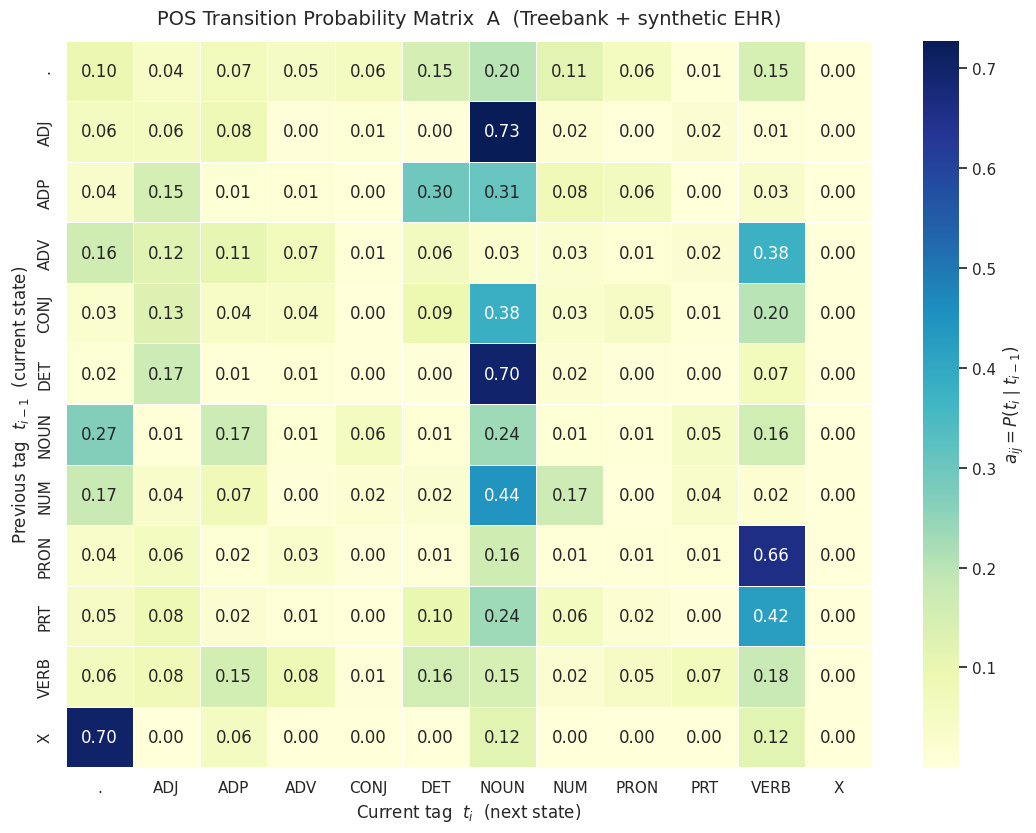

In [ ]:
A_df = pd.DataFrame(hmm.A, index=TAGS, columns=TAGS)

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(A_df, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5, linecolor="white",
            cbar_kws={"label": r"$a_{ij} = P(t_i \mid t_{i-1})$"}, ax=ax)
ax.set_title("POS Transition Probability Matrix  A  (Treebank + synthetic EHR)", fontsize=14, pad=12)
ax.set_xlabel("Current tag  $t_i$  (next state)")
ax.set_ylabel("Previous tag  $t_{i-1}$  (current state)")
plt.tight_layout(); plt.show()

## 5️⃣ The Forward pass (α)

**Idea.** Define the *forward variable*
$$\alpha_t(i)=P(o_1,o_2,\dots,o_t,\;q_t=S_i\mid\lambda)$$
= "the probability of having seen the first $t$ words **and** being in tag $S_i$ at time $t$", summed over **all** possible tag paths that lead there.

| Step | Formula | In words |
|---|---|---|
| Initialisation | $\alpha_1(i)=\pi_i\,b_i(o_1)$ | start in $S_i$, emit the first word |
| Induction | $\alpha_t(j)=\Big[\sum_{i=1}^{N}\alpha_{t-1}(i)\,a_{ij}\Big]\,b_j(o_t)$ | arrive from *any* previous tag, then emit |
| Termination | $P(O\mid\lambda)=\sum_{i=1}^{N}\alpha_T(i)$ | total probability of the sentence |

The sum over $i$ is the **"sum" in the Sum-Product algorithm**; the multiplication by $a_{ij}$ and $b_j(o_t)$ is the **"product"**.
Instead of enumerating $N^T$ tag sequences, dynamic programming needs only $O(T N^2)$ operations.

In matrix form, the induction is simply: `alpha[t] = (alpha[t-1] @ A) * E[t]`

In [ ]:
def forward_pass(pi, A, E):
    """Unscaled forward algorithm.
    pi: (N,)  A: (N,N)  E: (T,N) with E[t,i] = b_i(o_t).   Returns alpha (T,N)."""
    T, N = E.shape
    alpha = np.zeros((T, N))
    alpha[0] = pi * E[0]                          # initialisation
    for t in range(1, T):
        alpha[t] = (alpha[t - 1] @ A) * E[t]      # induction: sum over previous states, then emit
    return alpha

## 6️⃣ The Backward pass (β)

**Idea.** The *backward variable*
$$\beta_t(i)=P(o_{t+1},\dots,o_T\mid q_t=S_i,\lambda)$$
= "given that we are in tag $S_i$ at time $t$, how likely are the **remaining** words?" It carries information from the **right-hand context** back to position $t$.

| Step | Formula |
|---|---|
| Initialisation | $\beta_T(i)=1$ (nothing left to generate) |
| Induction | $\beta_t(i)=\sum_{j=1}^{N}a_{ij}\,b_j(o_{t+1})\,\beta_{t+1}(j)$ |
| Consistency check | $P(O\mid\lambda)=\sum_{i}\pi_i\,b_i(o_1)\,\beta_1(i)$ (must equal the forward result) |

Matrix form: `beta[t] = A @ (E[t+1] * beta[t+1])`

In [ ]:
def backward_pass(A, E):
    """Unscaled backward algorithm.  Returns beta (T,N)."""
    T, N = E.shape
    beta = np.zeros((T, N))
    beta[T - 1] = 1.0                                  # initialisation
    for t in range(T - 2, -1, -1):
        beta[t] = A @ (E[t + 1] * beta[t + 1])         # induction
    return beta

## 7️⃣ Marginal inference (γ): the exact posterior of every tag

Combining **left context** ($\alpha$) and **right context** ($\beta$):

$$\boxed{\;\gamma_t(i)=P(q_t=S_i\mid O,\lambda)=\frac{\alpha_t(i)\,\beta_t(i)}{P(O\mid\lambda)}=\frac{\alpha_t(i)\,\beta_t(i)}{\sum_{j=1}^{N}\alpha_t(j)\,\beta_t(j)}\;}$$

* This is an **exact** marginal: we sum over *all* $N^T$ tag sequences that pass through state $S_i$ at time $t$, without listing them.
* For every word, $\sum_i\gamma_t(i)=1$.
* **Posterior decoding:** $\hat q_t=\arg\max_i\gamma_t(i)$ maximises the expected number of *correctly tagged words* (Viterbi instead finds the single most probable *sequence*).
* The value $\max_i\gamma_t(i)$ is a built-in **confidence score**, very useful for clinical text where uncertain predictions should be flagged for human review.

### Numerical stability (scaling)
For long sentences $\alpha$ and $\beta$ become astronomically small (products of many probabilities) and underflow. The standard fix is to **normalise $\alpha$ at every step**:
$$\hat\alpha_t(i)=\frac{\alpha_t(i)}{c_t},\quad c_t=\sum_j \tilde\alpha_t(j),\qquad \hat\beta_t(i)=\frac{\tilde\beta_t(i)}{c_{t+1}},\qquad \log P(O\mid\lambda)=\sum_t\log c_t,\qquad \gamma_t(i)=\hat\alpha_t(i)\,\hat\beta_t(i)$$
We use the unscaled version to **show the maths** on a short sentence and the scaled version for **evaluation** on the full test set. Both give identical $\gamma$.

In [ ]:
def compute_gamma(alpha, beta):
    """gamma_t(i) = alpha_t(i) * beta_t(i) / P(O|lambda)  (row-normalised)."""
    g = alpha * beta
    return g / g.sum(axis=1, keepdims=True)


def forward_backward_scaled(pi, A, E):
    """Numerically stable forward-backward. Returns alpha_hat, beta_hat, gamma, log P(O|lambda)."""
    T, N = E.shape
    alpha_hat = np.zeros((T, N)); beta_hat = np.zeros((T, N)); c = np.zeros(T)

    a = pi * E[0]; c[0] = a.sum(); alpha_hat[0] = a / c[0]
    for t in range(1, T):
        a = (alpha_hat[t - 1] @ A) * E[t]
        c[t] = a.sum(); alpha_hat[t] = a / c[t]

    beta_hat[T - 1] = 1.0
    for t in range(T - 2, -1, -1):
        beta_hat[t] = (A @ (E[t + 1] * beta_hat[t + 1])) / c[t + 1]

    gamma = alpha_hat * beta_hat
    gamma /= gamma.sum(axis=1, keepdims=True)
    return alpha_hat, beta_hat, gamma, np.log(c).sum()

## 8️⃣ Step-by-step worked example on one clinical sentence

We run the full pipeline on

> *"The patient presents with severe chest pain and was prescribed aspirin ."*

and print the **emission likelihood matrix $E$, $\alpha$, $\beta$ and $\gamma$** (rows = words, columns = the 12 tags).
Notice how $\alpha$ and $\beta$ are tiny numbers (scientific notation) while $\gamma$ is a clean probability distribution for every word.

In [ ]:
sentence = "The patient presents with severe chest pain and was prescribed aspirin .".split()
gold     = ["DET","NOUN","VERB","ADP","ADJ","NOUN","NOUN","CONJ","VERB","VERB","NOUN","."]   # hand-annotated

E = hmm.emission_matrix(sentence)                   # E[t,i] = b_i(o_t)
alpha = forward_pass(hmm.pi, hmm.A, E)
beta  = backward_pass(hmm.A, E)
gamma = compute_gamma(alpha, beta)

row_labels = [f"{t+1:>2}. {w}" for t, w in enumerate(sentence)]
def show(M, name, sci=True):
    fmt = (lambda x: f"{x:.3e}") if sci else (lambda x: f"{x:.4f}")
    print(f"\n{'═'*30} {name} {'═'*30}")
    print(pd.DataFrame(M, index=row_labels, columns=TAGS).to_string(float_format=fmt))

show(E,     "EMISSION  E[t,i] = b_i(o_t)")
show(alpha, "FORWARD   alpha_t(i)")
show(beta,  "BACKWARD  beta_t(i)")
show(gamma, "POSTERIOR gamma_t(i)", sci=False)

# ---- consistency checks ----
p_fwd = alpha[-1].sum()                                          # sum_i alpha_T(i)
p_bwd = (hmm.pi * E[0] * beta[0]).sum()                          # sum_i pi_i b_i(o_1) beta_1(i)
print("\n" + "─"*90)
print(f"P(O|lambda) from forward  : {p_fwd:.6e}")
print(f"P(O|lambda) from backward : {p_bwd:.6e}   -> equal? {np.isclose(p_fwd, p_bwd)}")
print(f"Each row of gamma sums to 1? {np.allclose(gamma.sum(1), 1)}")
print(f"alpha_t . beta_t is the same at EVERY t (= P(O))? {np.allclose((alpha*beta).sum(1), p_fwd)}")

# ---- predictions ----
pred = [TAGS[i] for i in gamma.argmax(1)]
print("\nWORD-BY-WORD PREDICTION (posterior decoding)")
print(pd.DataFrame({"word": sentence, "gold": gold, "predicted": pred,
                    "confidence max gamma": gamma.max(1)}).to_string(index=False, float_format=lambda x: f"{x:.4f}"))


══════════════════════════════ EMISSION  E[t,i] = b_i(o_t) ══════════════════════════════
                       .       ADJ       ADP       ADV      CONJ       DET      NOUN       NUM      PRON       PRT      VERB         X
 1. The        8.951e-07 8.263e-04 1.112e-06 3.577e-06 4.178e-06 5.869e-01 1.109e-04 3.075e-04 3.548e-06 3.702e-06 7.555e-07 1.602e-04
 2. patient    8.951e-07 1.649e-06 1.112e-06 3.577e-06 4.178e-06 1.189e-06 3.723e-03 3.045e-06 3.548e-06 3.702e-06 7.555e-07 1.602e-04
 3. presents   8.951e-07 1.649e-06 1.112e-06 3.577e-06 4.178e-06 1.189e-06 3.686e-07 3.045e-06 3.548e-06 3.702e-06 2.017e-02 1.602e-04
 4. with       8.951e-07 1.649e-06 7.208e-02 3.577e-06 4.178e-06 1.189e-06 3.686e-07 3.045e-06 3.548e-06 3.702e-06 7.555e-07 1.602e-04
 5. severe     8.951e-07 1.006e-02 1.112e-06 3.577e-06 4.178e-06 1.189e-06 3.686e-07 3.045e-06 3.548e-06 3.702e-06 7.555e-07 1.602e-04
 6. chest      8.951e-07 1.649e-06 1.112e-06 3.577e-06 4.178e-06 1.189e-06 5.532e-04 3.045e-06 3.54

### ✅ Proof of exactness: brute-force enumeration
To prove the forward–backward marginals are **exact**, we compare them with a naïve computation that enumerates **every** possible tag sequence for a short phrase ($12^4=20{,}736$ paths), computes each path's joint probability

$$P(q_1,\dots,q_T,O)=\pi_{q_1}b_{q_1}(o_1)\prod_{t=2}^{T}a_{q_{t-1}q_t}\,b_{q_t}(o_t)$$

and sums the paths that pass through each state. For a 12-word sentence this would need $12^{12}\approx 9\times10^{12}$ paths, while forward–backward needs only $12\times12\times12$ operations.

In [ ]:
def brute_force_marginals(pi, A, E):
    """Naive exact marginals by enumerating all N^T tag sequences (only feasible for tiny T)."""
    T, N = E.shape
    marg = np.zeros((T, N)); Z = 0.0
    for path in itertools.product(range(N), repeat=T):
        p = pi[path[0]] * E[0, path[0]]
        for t in range(1, T):
            p *= A[path[t - 1], path[t]] * E[t, path[t]]
        Z += p
        for t, s in enumerate(path):
            marg[t, s] += p
    return marg / Z, Z

short = sentence[:4]                               # "The patient presents with"
E_s = hmm.emission_matrix(short)
g_bf, Z_bf = brute_force_marginals(hmm.pi, hmm.A, E_s)
a_s, b_s = forward_pass(hmm.pi, hmm.A, E_s), backward_pass(hmm.A, E_s)
g_fb = compute_gamma(a_s, b_s)
_, _, g_sc, loglik = forward_backward_scaled(hmm.pi, hmm.A, E_s)

print(f"Phrase: {' '.join(short)!r}  ->  {len(TAGS)}^{len(short)} = {len(TAGS)**len(short):,} tag sequences enumerated")
print(f"Max |gamma_bruteforce - gamma_forward_backward|  = {np.abs(g_bf - g_fb).max():.2e}")
print(f"Max |gamma_unscaled   - gamma_scaled|            = {np.abs(g_fb - g_sc).max():.2e}")
print(f"P(O): brute force {Z_bf:.6e} | forward {a_s[-1].sum():.6e} | exp(scaled log-lik) {np.exp(loglik):.6e}")
assert np.allclose(g_bf, g_fb) and np.allclose(g_fb, g_sc)
print("✅ Forward-Backward marginals are EXACT (match brute-force enumeration to machine precision).")

Phrase: 'The patient presents with'  ->  12^4 = 20,736 tag sequences enumerated
Max |gamma_bruteforce - gamma_forward_backward|  = 1.40e-14
Max |gamma_unscaled   - gamma_scaled|            = 4.44e-16
P(O): brute force 1.776238e-08 | forward 1.776238e-08 | exp(scaled log-lik) 1.776238e-08
✅ Forward-Backward marginals are EXACT (match brute-force enumeration to machine precision).


### 📊 Visualisation 2: Word-level marginal posteriors $\gamma_t(i)$

* **Stacked bar chart:** each bar is one word; the coloured segments are $P(\text{tag}=S_i\mid O)$ and add up to 1. A single dominant colour means a confident tag; several colours mean genuine ambiguity.
* **Heatmap + line plot:** the full $\gamma$ matrix and the model's confidence $\max_i\gamma_t(i)$ along the sentence.

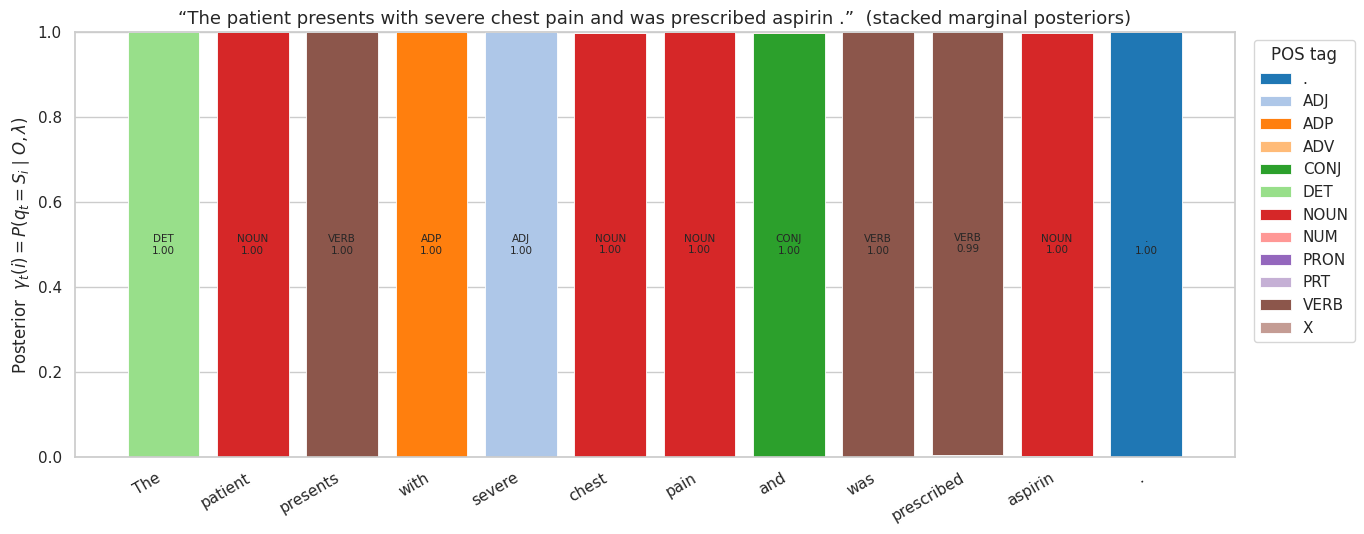

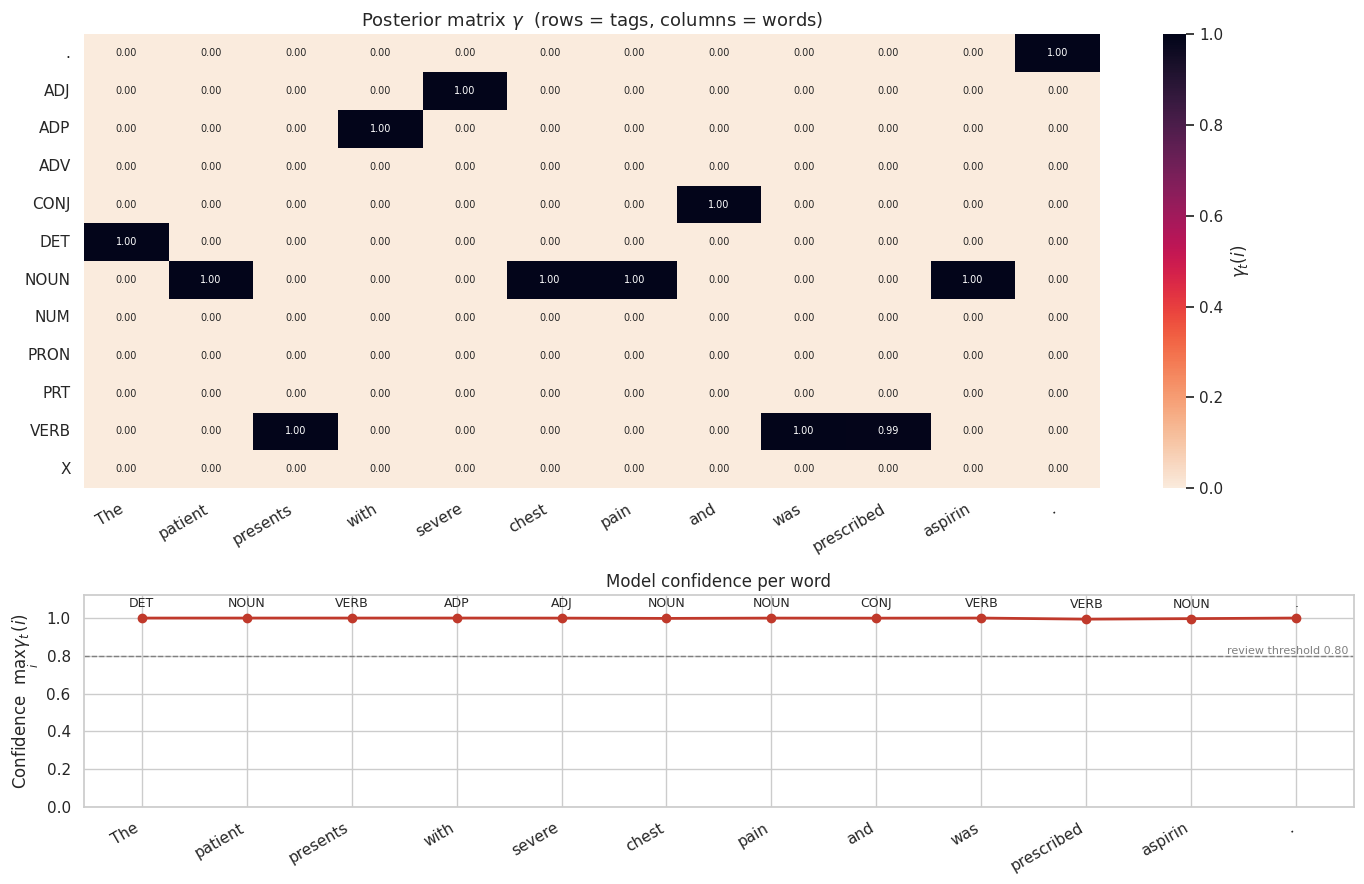

In [ ]:
def plot_posteriors(words, gamma, tags, title):
    T = len(words)
    palette = sns.color_palette("tab20", len(tags))

    # ---------- (a) stacked bar chart ----------
    fig, ax = plt.subplots(figsize=(max(10, 1.15 * T), 5.5))
    bottom = np.zeros(T)
    for j, tag in enumerate(tags):
        ax.bar(range(T), gamma[:, j], bottom=bottom, color=palette[j], label=tag, edgecolor="white", linewidth=0.6)
        for t in range(T):
            if gamma[t, j] > 0.08:
                ax.text(t, bottom[t] + gamma[t, j] / 2, f"{tag}\n{gamma[t, j]:.2f}",
                        ha="center", va="center", fontsize=7.5)
        bottom += gamma[:, j]
    ax.set_xticks(range(T)); ax.set_xticklabels(words, rotation=30, ha="right", fontsize=11)
    ax.set_ylabel(r"Posterior  $\gamma_t(i)=P(q_t=S_i\mid O,\lambda)$"); ax.set_ylim(0, 1)
    ax.set_title(title + "  (stacked marginal posteriors)", fontsize=13)
    ax.legend(title="POS tag", bbox_to_anchor=(1.01, 1), loc="upper left", ncol=1)
    plt.tight_layout(); plt.show()

    # ---------- (b) heatmap of gamma + confidence line ----------
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(max(10, 1.15 * T), 9), gridspec_kw={"height_ratios": [3, 1.4]})
    sns.heatmap(gamma.T, annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=1, ax=ax1,
                xticklabels=words, yticklabels=tags, cbar_kws={"label": r"$\gamma_t(i)$"}, annot_kws={"size": 7})
    ax1.set_title(r"Posterior matrix $\gamma$  (rows = tags, columns = words)", fontsize=13)
    ax1.set_xticklabels(words, rotation=30, ha="right")
    conf = gamma.max(1); best = [tags[i] for i in gamma.argmax(1)]
    ax2.plot(range(T), conf, "o-", color="#c0392b", lw=2)
    for t in range(T):
        ax2.annotate(best[t], (t, conf[t]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
    ax2.axhline(0.8, ls="--", color="gray", lw=1); ax2.text(T - 0.5, 0.81, "review threshold 0.80", ha="right", fontsize=8, color="gray")
    ax2.set_xticks(range(T)); ax2.set_xticklabels(words, rotation=30, ha="right")
    ax2.set_ylim(0, 1.12); ax2.set_ylabel(r"Confidence  $\max_i\gamma_t(i)$")
    ax2.set_title("Model confidence per word", fontsize=12)
    plt.tight_layout(); plt.show()

plot_posteriors(sentence, gamma, TAGS, "“The patient presents with severe chest pain and was prescribed aspirin .”")

The sentence above is unambiguous, so almost every bar is a single colour. Now a sentence with **genuinely ambiguous words**:
`report` and `monitor` can each be a NOUN or a VERB. Watch how the bars for those two words split between colours. This is the information a single "best tag" output would hide.

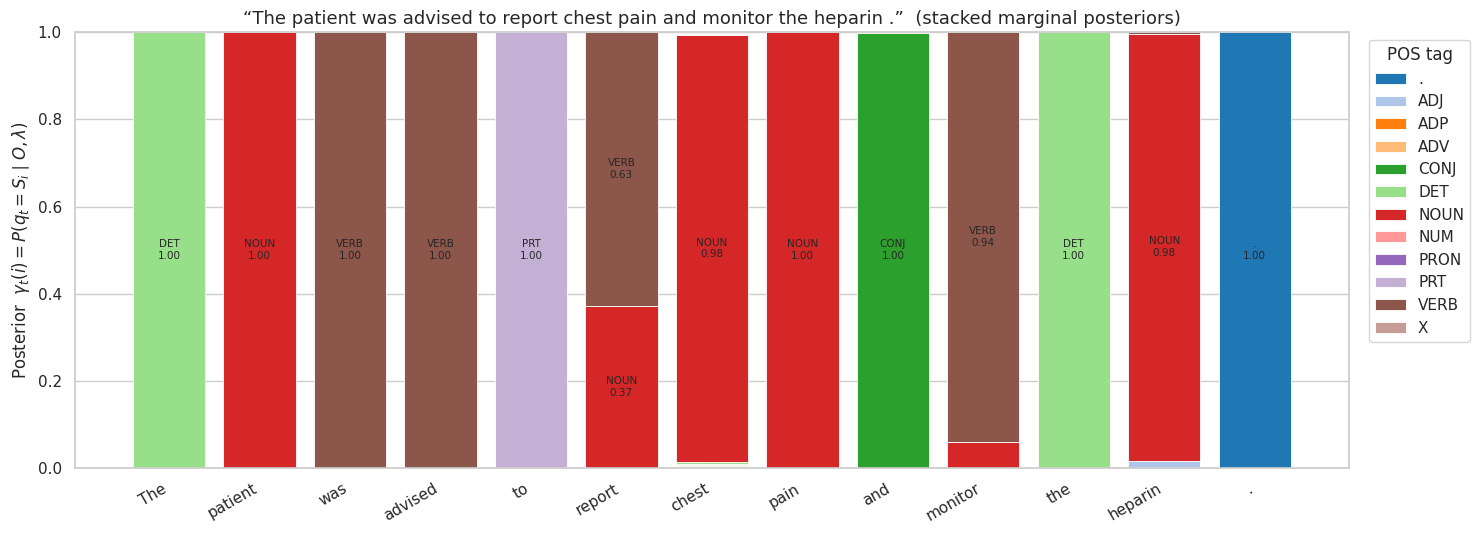

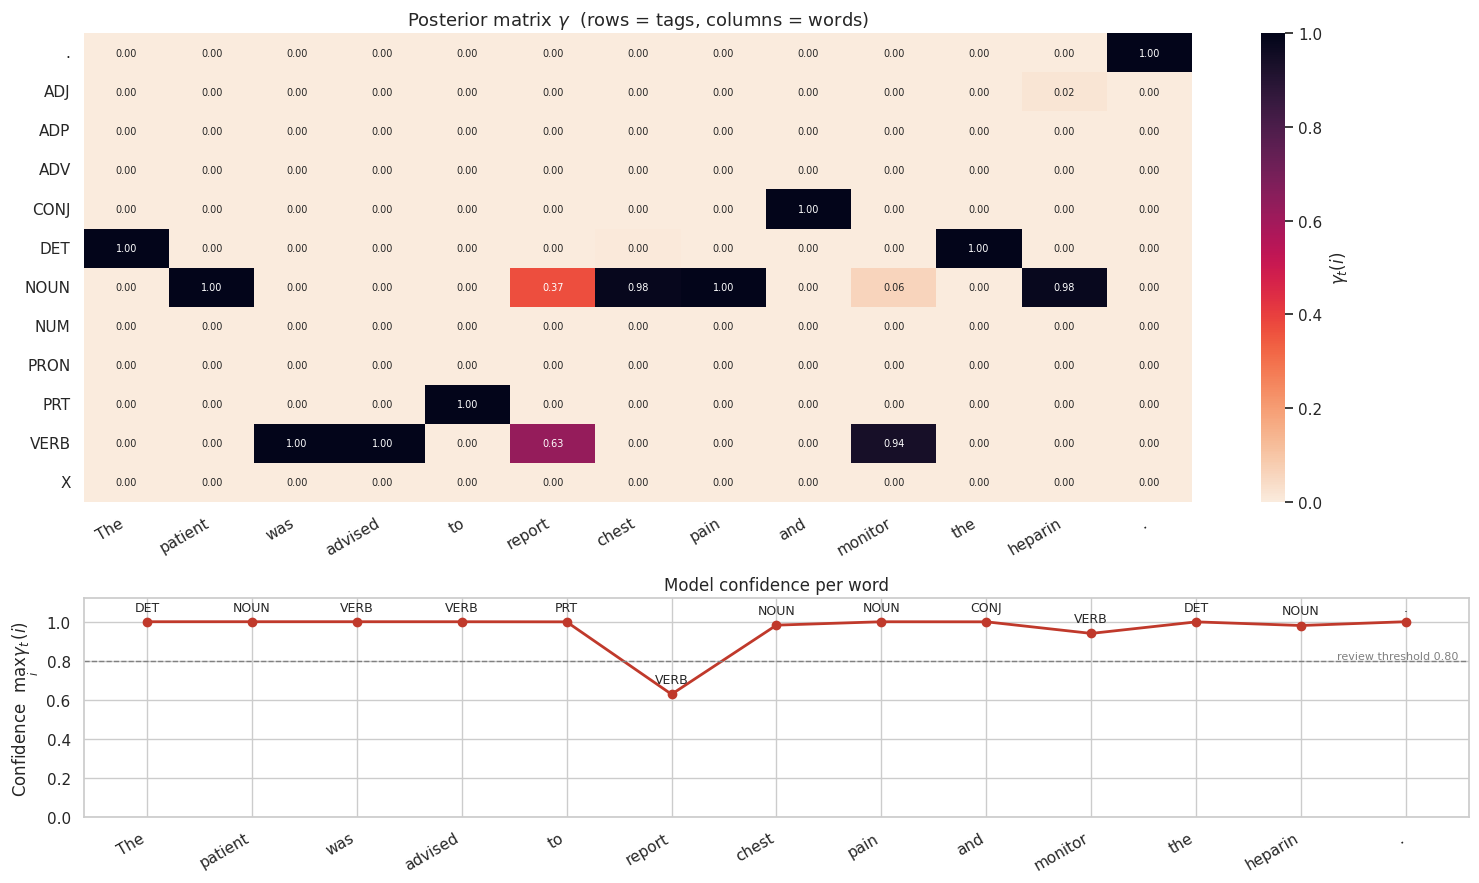

In [ ]:
amb_sentence = "The patient was advised to report chest pain and monitor the heparin .".split()   # 'heparin' is an unseen word
g_amb = forward_backward_scaled(hmm.pi, hmm.A, hmm.emission_matrix(amb_sentence))[2]
plot_posteriors(amb_sentence, g_amb, TAGS, "“The patient was advised to report chest pain and monitor the heparin .”")

## 9️⃣ Evaluation: accuracy and confusion matrix

For every test sentence we run the (scaled) forward–backward algorithm and predict $\hat q_t=\arg\max_i\gamma_t(i)$. We evaluate on:

1. **Synthetic EHR test set**: clinical sentences, including *unseen* clinical words (OOV).
2. **Treebank held-out test set**: general English, as a sanity check that the base model is a sound tagger.
3. **A hand-written, hand-annotated mini set** of realistic EHR sentences that are **not** generated from our templates.

> ⚠️ **How to read these numbers honestly.** The synthetic EHR sentences come from a small set of templates, so near-perfect accuracy there is *expected*. It confirms that the pipeline and the unseen-word handling work, but it is **not** a claim about real hospital notes. The **Penn Treebank test (~95%)** is the more realistic benchmark of the tagger itself, and real clinical notes (abbreviations, fragments, typos) would be harder still. Both are reported so you can discuss this limitation openly.

In [ ]:
def tag_sentence(model, words):
    E = model.emission_matrix(words)
    _, _, g, loglik = forward_backward_scaled(model.pi, model.A, E)
    return g, loglik

def evaluate(model, tagged_sents):
    y_true, y_pred, is_oov = [], [], []
    for sent in tagged_sents:
        words = [w for w, _ in sent]
        g, _ = tag_sentence(model, words)
        y_pred += list(g.argmax(1))
        y_true += [model.tag2i[t] for _, t in sent]
        is_oov += [not model.is_known(w) for w in words]
    return np.array(y_true), np.array(y_pred), np.array(is_oov)

def confusion(y_true, y_pred, N):
    cm = np.zeros((N, N), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

def per_tag_report(cm, tags):
    tp = np.diag(cm).astype(float)
    prec = np.divide(tp, cm.sum(0), out=np.zeros_like(tp), where=cm.sum(0) > 0)
    rec  = np.divide(tp, cm.sum(1), out=np.zeros_like(tp), where=cm.sum(1) > 0)
    f1   = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(tp), where=(prec + rec) > 0)
    return pd.DataFrame({"precision": prec, "recall": rec, "F1": f1, "support": cm.sum(1)}, index=tags)

# ---------- 1) synthetic clinical test ----------
yt_c, yp_c, oov_c = evaluate(hmm, ehr_test)
# ---------- 2) Treebank test ----------
yt_t, yp_t, oov_t = evaluate(hmm, tb_test)

def acc(a, b, mask=None):
    return (a == b).mean() if mask is None else (a[mask] == b[mask]).mean()

summary = pd.DataFrame({
    "tokens":            [len(yt_c), len(yt_t)],
    "accuracy (all)":    [acc(yt_c, yp_c), acc(yt_t, yp_t)],
    "unseen-word share": [oov_c.mean(), oov_t.mean()],
    "accuracy (unseen words)": [acc(yt_c, yp_c, oov_c) if oov_c.any() else np.nan,
                                acc(yt_t, yp_t, oov_t)],
}, index=["Synthetic EHR test", "Treebank test"])
print(summary.to_string(float_format=lambda x: f"{x:.4f}"))

# ---------- 3) hand-written realistic EHR sentences (NOT from templates) ----------
HAND = [
 ("The patient presents with severe chest pain and was prescribed aspirin .",
  "DET NOUN VERB ADP ADJ NOUN NOUN CONJ VERB VERB NOUN ."),
 ("Patient denies nausea , vomiting or fever .",
  "NOUN VERB NOUN . NOUN CONJ NOUN ."),
 ("She reports persistent cough for three days .",
  "PRON VERB ADJ NOUN ADP NUM NOUN ."),
 ("Blood pressure was elevated on admission .",
  "NOUN NOUN VERB ADJ ADP NOUN ."),
 ("The ECG showed no acute abnormality .",
  "DET NOUN VERB DET ADJ NOUN ."),
 ("He was started on metformin 500 mg for diabetes .",
  "PRON VERB VERB ADP NOUN NUM NOUN ADP NOUN ."),
]
hand_sents = [list(zip(s.split(), t.split())) for s, t in HAND]
yt_h, yp_h, oov_h = evaluate(hmm, hand_sents)
print(f"\nHand-annotated realistic EHR sentences: {acc(yt_h, yp_h):.4f} token accuracy ({len(yt_h)} tokens, "
      f"{oov_h.sum()} unseen)")

                    tokens  accuracy (all)  unseen-word share  accuracy (unseen words)
Synthetic EHR test    3450          1.0000             0.0281                   1.0000
Treebank test        18396          0.9506             0.1013                   0.8203

Hand-annotated realistic EHR sentences: 1.0000 token accuracy (52 tokens, 1 unseen)


### 📊 Visualisation 3: Confusion matrices (true vs predicted tags)

Left: raw **counts**. Right: **row-normalised** (each row = a true tag; the diagonal is the per-tag recall). Off-diagonal cells reveal systematic confusions. The synthetic-EHR matrix is (almost) perfectly diagonal, as expected for template data. The **Treebank** matrix (second figure) shows the realistic confusions: `NOUN ↔ ADJ`, `NOUN ↔ VERB` and `ADV ↔ ADP`.

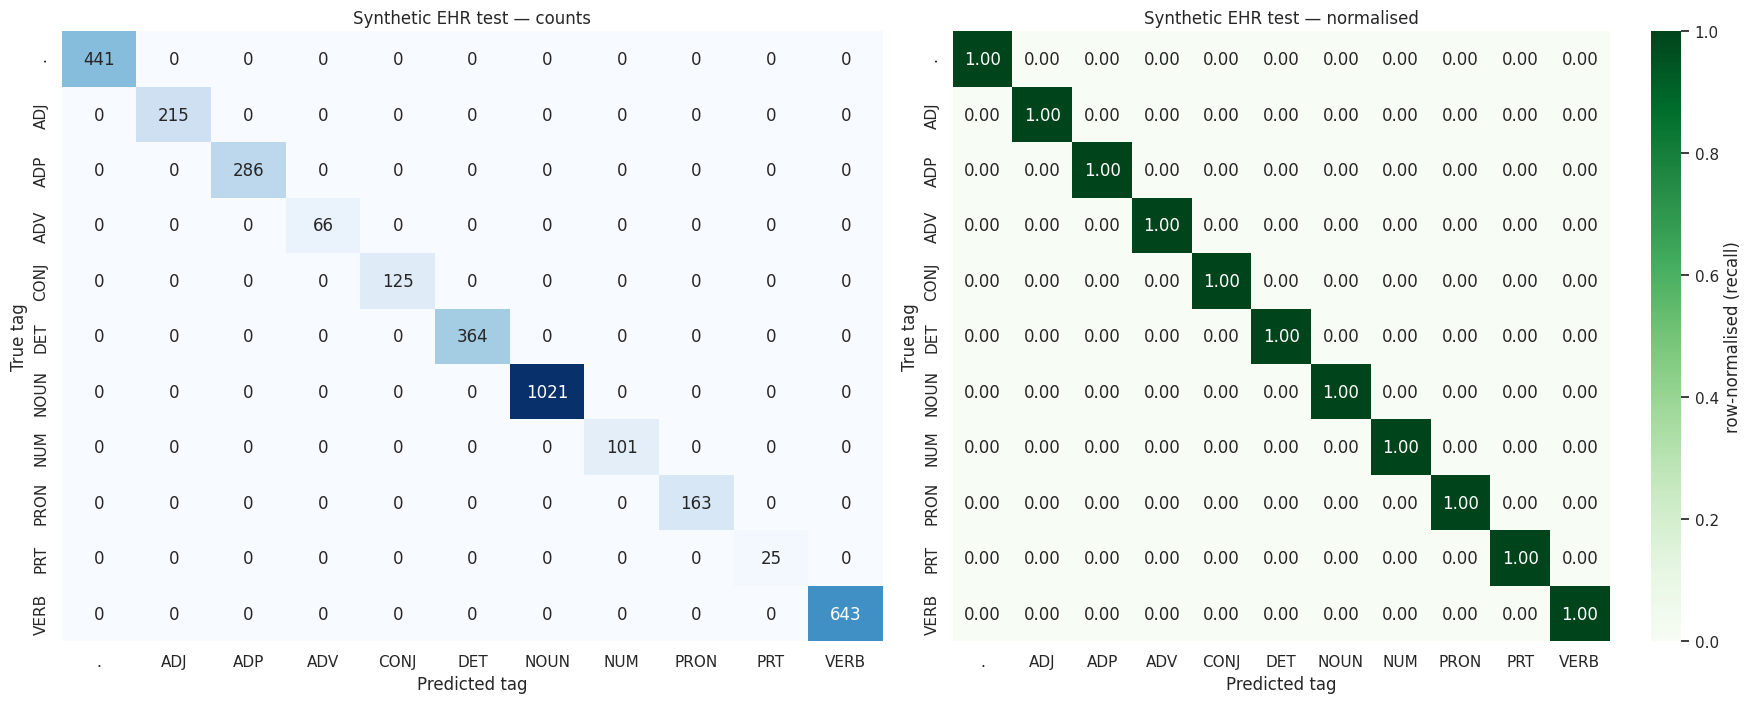

Per-tag report: synthetic EHR test
      precision  recall    F1  support
.         1.000   1.000 1.000      441
ADJ       1.000   1.000 1.000      215
ADP       1.000   1.000 1.000      286
ADV       1.000   1.000 1.000       66
CONJ      1.000   1.000 1.000      125
DET       1.000   1.000 1.000      364
NOUN      1.000   1.000 1.000     1021
NUM       1.000   1.000 1.000      101
PRON      1.000   1.000 1.000      163
PRT       1.000   1.000 1.000       25
VERB      1.000   1.000 1.000      643


In [ ]:
def plot_confusion(cm, tags, title):
    present = np.where((cm.sum(0) + cm.sum(1)) > 0)[0]            # hide tags that never occur
    cm_s = cm[np.ix_(present, present)]; lab = [tags[i] for i in present]
    norm = np.divide(cm_s, cm_s.sum(1, keepdims=True), out=np.zeros(cm_s.shape), where=cm_s.sum(1, keepdims=True) > 0)
    fig, axes = plt.subplots(1, 2, figsize=(18, 7.2))
    sns.heatmap(cm_s, annot=True, fmt="d", cmap="Blues", xticklabels=lab, yticklabels=lab, ax=axes[0], cbar=False)
    axes[0].set_title(title + " — counts")
    sns.heatmap(norm, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, xticklabels=lab, yticklabels=lab,
                ax=axes[1], cbar_kws={"label": "row-normalised (recall)"})
    axes[1].set_title(title + " — normalised")
    for ax in axes: ax.set_xlabel("Predicted tag"); ax.set_ylabel("True tag")
    plt.tight_layout(); plt.show()

cm_clin = confusion(yt_c, yp_c, hmm.N)
cm_tb   = confusion(yt_t, yp_t, hmm.N)

plot_confusion(cm_clin, TAGS, "Synthetic EHR test")
print("Per-tag report: synthetic EHR test")
print(per_tag_report(cm_clin, TAGS).query("support > 0").to_string(float_format=lambda x: f"{x:.3f}"))

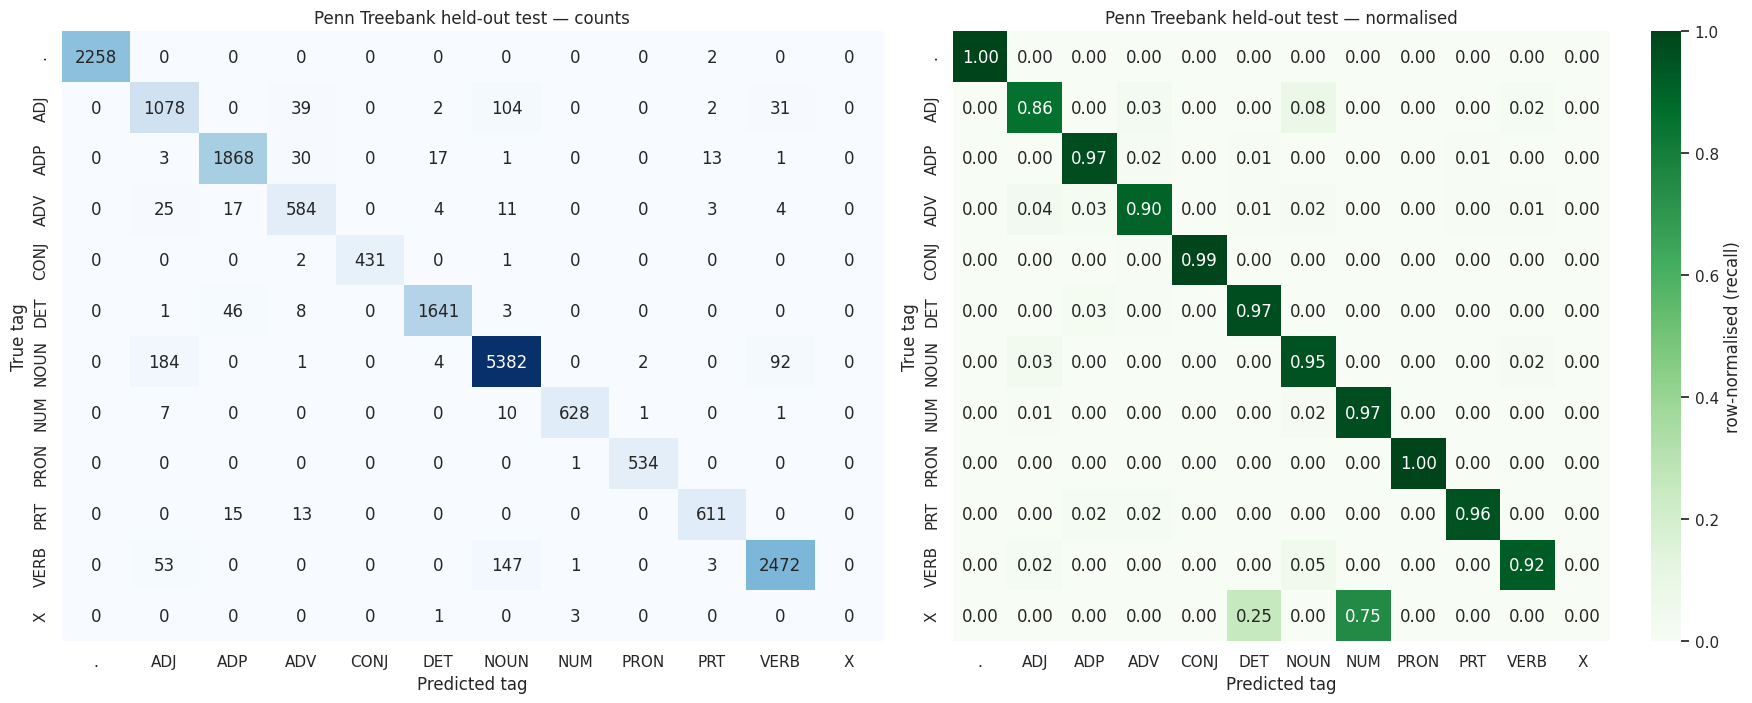

Per-tag report: Treebank test
      precision  recall    F1  support
.         1.000   0.999 1.000     2260
ADJ       0.798   0.858 0.827     1256
ADP       0.960   0.966 0.963     1933
ADV       0.863   0.901 0.882      648
CONJ      1.000   0.993 0.997      434
DET       0.983   0.966 0.974     1699
NOUN      0.951   0.950 0.951     5665
NUM       0.992   0.971 0.981      647
PRON      0.994   0.998 0.996      535
PRT       0.964   0.956 0.960      639
VERB      0.950   0.924 0.937     2676
X         0.000   0.000 0.000        4

Most frequent clinical-test errors  (word, true -> predicted):
  (none: template-generated test data is easy; see the Treebank matrix for realistic errors)


In [ ]:
plot_confusion(cm_tb, TAGS, "Penn Treebank held-out test")
print("Per-tag report: Treebank test")
print(per_tag_report(cm_tb, TAGS).query("support > 0").to_string(float_format=lambda x: f"{x:.3f}"))

# which words did the clinical model get wrong?
errs = collections.Counter()
for sent in ehr_test:
    words = [w for w, _ in sent]; g, _ = tag_sentence(hmm, words)
    for (w, t), p in zip(sent, g.argmax(1)):
        if TAGS[p] != t: errs[(w, t, TAGS[p])] += 1
print("\nMost frequent clinical-test errors  (word, true -> predicted):")
if not errs: print("  (none: template-generated test data is easy; see the Treebank matrix for realistic errors)")
for (w, t, p), n in errs.most_common(8): print(f"  {w:<14} {t:>5} -> {p:<5} x{n}")

## 🔟 Posterior inference on unstructured EHR sentences

Now we use the **marginals as a decision-support signal**. For each realistic clinical sentence we show

* the predicted tag and its posterior probability for every word, and
* tokens whose confidence falls below **0.80**, flagged **⚠ REVIEW**. A deterministic tagger (Viterbi) would give no such warning.

The last two sentences are deliberately hard (`report` / `monitor` / `cardiac monitor`). The model is uncertain there and **may even choose the wrong tag**, but the low posterior flags exactly those tokens. That is the practical value of marginal inference.

In [ ]:
def tag_table(words, gamma, thresh=0.80):
    rows = []
    for w, g in zip(words, gamma):
        order = np.argsort(-g)[:3]
        rows.append({"word": w,
                     "best tag": TAGS[order[0]], "P(best)": g[order[0]],
                     "2nd": f"{TAGS[order[1]]} ({g[order[1]]:.2f})",
                     "3rd": f"{TAGS[order[2]]} ({g[order[2]]:.2f})",
                     "flag": "⚠ REVIEW" if g[order[0]] < thresh else ""})
    return pd.DataFrame(rows)

for text in ["Patient denies nausea , vomiting or fever .",
             "She reports persistent cough for three days .",
             "The ECG showed no acute abnormality .",
             "He was started on metformin 500 mg for diabetes .",
             "The patient was advised to report chest pain and monitor the heparin .",
             "Cardiac monitor showed elevated heart rate ."]:
    words = text.split(); g, ll = tag_sentence(hmm, words)
    print(f"\n▶ {text}      [log P(O) = {ll:.2f}]")
    print(tag_table(words, g).to_string(index=False, float_format=lambda x: f"{x:.3f}"))


▶ Patient denies nausea , vomiting or fever .      [log P(O) = -44.21]
    word best tag  P(best)         2nd        3rd flag
 Patient     NOUN    0.996 PRON (0.00) ADV (0.00)     
  denies     VERB    0.999 CONJ (0.00) ADP (0.00)     
  nausea     NOUN    0.999  ADV (0.00) PRT (0.00)     
       ,        .    1.000 CONJ (0.00) ADP (0.00)     
vomiting     NOUN    1.000  NUM (0.00)   . (0.00)     
      or     CONJ    1.000  ADP (0.00)   . (0.00)     
   fever     NOUN    1.000  ADV (0.00) NUM (0.00)     
       .        .    1.000 CONJ (0.00) ADP (0.00)     

▶ She reports persistent cough for three days .      [log P(O) = -42.45]
      word best tag  P(best)         2nd        3rd flag
       She     PRON    1.000  ADV (0.00)   X (0.00)     
   reports     VERB    0.997 NOUN (0.00) ADV (0.00)     
persistent      ADJ    0.999  DET (0.00) PRT (0.00)     
     cough     NOUN    1.000  ADJ (0.00) NUM (0.00)     
       for      ADP    0.999  PRT (0.00)   . (0.00)     
     three      N

### 🔍 Why marginals matter: context resolves ambiguity

The word **`monitor`** can be a verb (*"will monitor the pain"*) or a noun (*"the monitor showed ..."*). The HMM disambiguates it from **both neighbours**. Left context comes from $\alpha$, right context from $\beta$. The same word receives a completely different posterior in each sentence.

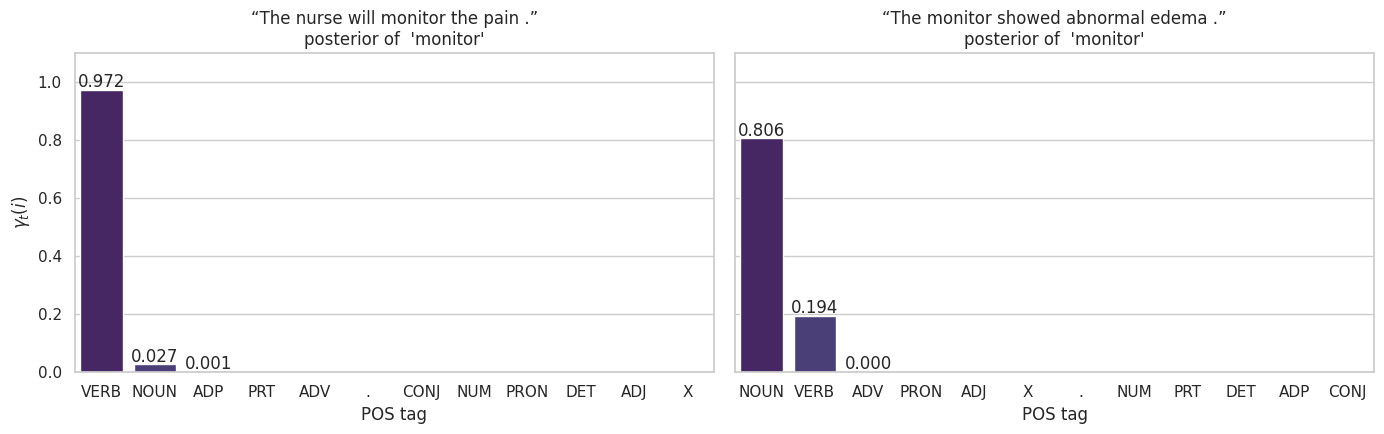

In [ ]:
pairs = [("The nurse will monitor the pain .", 3), ("The monitor showed abnormal edema .", 1)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (text, pos) in zip(axes, pairs):
    words = text.split(); g, _ = tag_sentence(hmm, words)
    order = np.argsort(-g[pos])
    tag_order = [TAGS[i] for i in order]
    sns.barplot(x=tag_order, y=g[pos][order], hue=tag_order, palette="viridis", legend=False, ax=ax)
    for k, i in enumerate(order[:3]): ax.text(k, g[pos][i] + 0.01, f"{g[pos][i]:.3f}", ha="center")
    ax.set_title(f"“{text}”\nposterior of  '{words[pos]}'"); ax.set_ylim(0, 1.1)
    ax.set_xlabel("POS tag"); ax.set_ylabel(r"$\gamma_t(i)$")
plt.tight_layout(); plt.show()

## 1️⃣1️⃣ From POS posteriors to clinical information extraction

With reliable tags we can pull structured facts out of free text using simple chunk rules:

* **Clinical entities** = maximal runs of `ADJ`/`NOUN` tokens that contain at least one `NOUN` (e.g. *severe chest pain*, *aspirin*, *hypertension*).
* **Quantities** = `NUM` followed by a `NOUN` (e.g. *500 mg*, *three days*).
* **Clinical actions** = main `VERB`s (auxiliaries such as *was/is/has/will* are skipped).
* Each extracted item gets a **confidence = mean posterior** of its tokens, a direct benefit of marginal inference.

In [ ]:
AUX = {"was", "is", "has", "had", "will", "were", "been", "be", "are", "have"}

def extract_clinical_info(words, gamma):
    tags = [TAGS[i] for i in gamma.argmax(1)]; conf = gamma.max(1)
    items, t = [], 0
    while t < len(words):
        if tags[t] in ("ADJ", "NOUN"):
            s = t
            while t < len(words) and tags[t] in ("ADJ", "NOUN"): t += 1
            if any(tags[k] == "NOUN" for k in range(s, t)):
                items.append(("ENTITY", " ".join(words[s:t]), conf[s:t].mean()))
        elif tags[t] == "NUM" and t + 1 < len(words) and tags[t + 1] == "NOUN":
            items.append(("QUANTITY", f"{words[t]} {words[t+1]}", conf[t:t + 2].mean())); t += 2
        elif tags[t] == "VERB" and words[t].lower() not in AUX:
            items.append(("ACTION", words[t], conf[t])); t += 1
        else:
            t += 1
    return pd.DataFrame(items, columns=["type", "text", "confidence"])

record = ("The patient presents with severe chest pain and was prescribed aspirin . "
          "He has a history of hypertension and diabetes . "
          "He is currently taking metformin 500 mg . "
          "The ECG showed no acute abnormality . "
          "She reports persistent cough for three days .")
print("EHR NOTE:\n", record, "\n")
all_rows = []
for sent in record.split(" . "):
    sent = sent.strip().rstrip(".").strip()
    if not sent: continue
    words = (sent + " .").split(); g, _ = tag_sentence(hmm, words)
    df = extract_clinical_info(words, g); df.insert(0, "sentence", sent[:38] + "…")
    all_rows.append(df)
print(pd.concat(all_rows, ignore_index=True).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

EHR NOTE:
 The patient presents with severe chest pain and was prescribed aspirin . He has a history of hypertension and diabetes . He is currently taking metformin 500 mg . The ECG showed no acute abnormality . She reports persistent cough for three days . 

                               sentence     type              text  confidence
The patient presents with severe chest…   ENTITY           patient       1.000
The patient presents with severe chest…   ACTION          presents       1.000
The patient presents with severe chest…   ENTITY severe chest pain       0.999
The patient presents with severe chest…   ACTION        prescribed       0.994
The patient presents with severe chest…   ENTITY           aspirin       0.997
He has a history of hypertension and d…   ENTITY           history       1.000
He has a history of hypertension and d…   ENTITY      hypertension       1.000
He has a history of hypertension and d…   ENTITY          diabetes       1.000
He is currently taking metfor

## ✅ Summary and talking points for your evaluation

**What we built.** A first-order HMM POS tagger whose parameters $(\pi, A, B)$ were learned by counting on Penn Treebank + synthetic EHR text, with **forward ($\alpha$), backward ($\beta$) and marginal ($\gamma$) passes implemented from scratch in NumPy**.

**Key results to quote** (see the output cells above for the exact numbers from your run):
* Forward–backward marginals match brute-force enumeration to machine precision → the inference is **exact**.
* $P(O\mid\lambda)$ computed from the forward pass equals the one computed from the backward pass.
* ~95% token accuracy on held-out Penn Treebank text; near-perfect on the template-generated EHR test set (expected: it is synthetic), including words never seen in training thanks to the rare-word signature trick + context.
* Marginals give per-word **confidence scores** that can flag uncertain tokens for review.

### Likely viva questions and short answers

| Question | Answer |
|---|---|
| Why forward–backward instead of enumerating all tag sequences? | $N^T$ paths vs $O(TN^2)$ operations via dynamic programming (sum-product on a chain). |
| What does $\alpha_t(i)$ mean? | Joint probability of the first $t$ words *and* tag $S_i$ at $t$ (left context). |
| What does $\beta_t(i)$ mean? | Probability of the remaining words given tag $S_i$ at $t$ (right context). |
| Why is $\gamma_t(i)=\alpha_t(i)\beta_t(i)/P(O)$? | By conditional independence given $q_t$, the future and the past factorise; dividing by $P(O)$ normalises. |
| Forward–backward vs Viterbi? | FB gives per-position marginals (maximises expected # correct tags); Viterbi gives the single best sequence (maximises sequence probability). |
| Why scaling? | Products of many probabilities underflow; normalising each step keeps numbers in range and $\log P(O)=\sum\log c_t$. |
| Why do we need smoothing? | Zero counts would make some sequences impossible and break the product. |
| Limitations? | First-order Markov assumption; words are conditionally independent given tags; synthetic EHR text is simpler than real notes (e.g. MIMIC); no abbreviations or negation scope. |
| Future work | Baum–Welch (unsupervised EM uses exactly these $\alpha,\beta$ to compute $\xi_t(i,j)$), second-order HMM, CRF / BiLSTM-CRF / ClinicalBERT, real de-identified clinical corpora. |